# Stage B 跨阶段对比（B-3 → B-4 → B-5）

只读取 G9 JSON 和训练 `loss.log`，不加载模型、不用 GPU、不影响训练。从 `stage_b_ckpt_eval.ipynb` 抽出跨阶段对比部分，不画各阶段自己的 11 组图。

- 横轴为累计步数：各阶段步数 + `start_step`。B-4 第 0 步 = B-3 105k；B-5 第 0 步 = B-4 500k（LoRA 合并后）。竖点线标出各阶段起点；每个阶段只画到下一阶段的起点。
- **C1** 训练 loss（主进程，1,000 步 trailing mean）；**C2** 留出集 matched 误差；**C3** blank / alt / wrong 比值（含 95% CI）；最后是各阶段汇总表。虚线把上一阶段起点处的评估与下一阶段第一次评估连起来，只连相同 query 数的点。
- matched 等是归一化 delta 动作 MSE，与训练 flow loss 量纲不同；比值 = 换示教后误差 / matched 误差。
- 按顺序运行全部单元格；有新的 checkpoint / G9 后重跑即可。导出到 `stage_b/reports/stage_compare_b3_b5/`（同名覆盖）。

In [26]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import io
import json
import math

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string(index=False) if isinstance(obj, pd.DataFrame) else obj)

REPO_ROOT = Path('/home/jovyan/workspace/mytbot')  # 早期 G9 JSON 的 ckpt 是相对它的路径
STAGE_B = REPO_ROOT / 'outputs/BPv4CDX/stage_b'
G9_DIR = STAGE_B / 'g9'

# ===== 主要输入：每个阶段一条 =====
# start_step：该阶段第 0 步在累计步数轴上的位置。B-4 从 B-3 105k 初始化；B-5 从 B-4 500k（合并 LoRA）初始化。
STAGES = [
    {'name': 'B-3', 'run_root': STAGE_B / 'b3_main', 'eval_glob': 'b3_*.json', 'start_step': 0},
    {'name': 'B-4', 'run_root': STAGE_B / 'b4_main', 'eval_glob': 'b4_*.json', 'start_step': 105000},
    {'name': 'B-5', 'run_root': STAGE_B / 'b5_main', 'eval_glob': 'b5_*.json', 'start_step': 605000},
]

# 同一阶段同一 checkpoint、同一 query 数有重复评估时报错，用这里排除旧文件（例如 {'b2_010k.json'}）
# b5_init_merged.json 是合并后起点（不是 B-5 run 的 checkpoint）的评估，连接线用 B-4 500k
EXCLUDE_FILES = {'b5_init_merged.json'}
QUERY_COUNTS = None      # 例如 [100]；None = 全部，按 query 数分开连线

MIN_STEP = 0             # 各阶段自己的步数范围
MAX_STEP = None
ZOOM_FROM_STEP = {'B-3': 20000, 'B-4': 2000}  # 训练 loss 放大图起点；未列出的阶段 = 0
LOG_FREQ_OVERRIDE = None # None = 从 checkpoint 的 train_config.json 读，还没有 checkpoint 时由 loss.log 步长推断
SMOOTH_STEPS = 1000      # 训练曲线只做 trailing mean
WINDOW_STEPS = (100, 1000, 5000)
SELECT_STEP = {}         # 分组 CI 图的 checkpoint，如 {'B-3': 65000}；未列出 = 该阶段最新已评估
SELECT_QUERIES = None    # None = 选中 checkpoint 中最大的 query 数

# ===== 报告输出 =====
EXPORT = True
EXPORT_DIRS = {}         # 各阶段导出目录；未列出 = <run>/reports/checkpoint_eval
COMPARE_DIR = STAGE_B / 'reports' / 'stage_compare_b3_b5'
FORMATS = ('png', 'pdf', 'svg')
DPI = 300
FIGSIZE_ROW = (14, 4.3)

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.22,
    'legend.fontsize': 8, 'figure.dpi': 110, 'figure.max_open_warning': 0,  # 图留到最后统一导出
    'savefig.facecolor': 'white', 'pdf.fonttype': 42, 'svg.fonttype': 'none',
})
pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 200)
COLORS = {'matched': '#0072B2', 'blank': '#D55E00', 'alt': '#009E73', 'wrong': '#CC79A7'}
STAGE_COLORS = {'B-2': '#7F7F7F', 'B-3': '#0072B2', 'B-4': '#D55E00', 'B-5': '#009E73'}
MARKERS = ('o', 's', '^', 'D')
LINESTYLES = ('-', '--', ':', '-.')

In [27]:
# ===== 读取：每个阶段一个 ctx（新增 checkpoint / G9 后从这里重跑） =====
def clipped(df):
    out = df[df['step'] >= MIN_STEP]
    if MAX_STEP is not None:
        out = out[out['step'] <= MAX_STEP]
    return out.sort_values('step').reset_index(drop=True)


def numeric(value):
    try:
        return float(value) if value is not None else np.nan
    except (TypeError, ValueError):
        return np.nan


def resolve_run(root):
    root = Path(root).expanduser().resolve()
    if (root / 'loss.log').is_file():
        return root
    candidates = sorted(p.parent for p in root.glob('*/loss.log'))
    if len(candidates) > 1:
        raise ValueError(f'{root} 下有 {len(candidates)} 个 run，请把 run_root 改成具体时间戳目录：{candidates}')
    return candidates[0].resolve() if candidates else None


def load_loss(path, issues):
    # 日志仍在写入时只取到最后一个换行为止的完整行
    text = path.read_text(encoding='utf-8')
    text = text[:text.rfind('\n') + 1]
    rows = []
    for r in csv.DictReader(io.StringIO(text)):
        try:
            step, loss = int(r['step']), float(r['loss'])
            if step < 1 or not np.isfinite(loss):
                raise ValueError('invalid step/loss')
        except (TypeError, KeyError, ValueError):
            issues.append(f'{path}: skipped malformed CSV row')
            continue
        rows.append({**{k: numeric(v) for k, v in r.items() if k != 'timestamp'},
                     'step': step, 'loss': loss, 'timestamp': r.get('timestamp')})
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    df = df.drop_duplicates('step', keep='last').sort_values('step').reset_index(drop=True)
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce', utc=True)
    df['elapsed_hours'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 3600
    return df


def train_config(run):
    files = sorted((run / 'checkpoints').glob('[0-9]*/pretrained_model/train_config.json'))
    return (json.loads(files[-1].read_text()), files[-1]) if files else ({}, None)


def log_freq(train, cfg_json):
    if LOG_FREQ_OVERRIDE is not None:
        return int(LOG_FREQ_OVERRIDE)
    if 'log_freq' in cfg_json:
        return int(cfg_json['log_freq'])
    diffs = np.diff(train['step'].to_numpy())
    return int(np.median(diffs)) if len(diffs) else int(train['step'].iloc[0])


def read_evaluations(root, run, eval_glob, issues):
    records = []
    for p in sorted(root.glob(eval_glob)):
        if p.name in EXCLUDE_FILES:
            continue
        try:
            d = json.loads(p.read_text())
        except (OSError, json.JSONDecodeError) as exc:
            issues.append(f'{p.name}: skipped incomplete JSON: {exc}')
            continue
        try:
            ckpt = Path(d['ckpt']).expanduser()  # 权重文件不必仍存在，只用路径匹配 run
            ckpt = (ckpt if ckpt.is_absolute() else REPO_ROOT / ckpt).resolve()
            step, checkpoint_run = int(ckpt.parent.name), ckpt.parents[2]
        except (KeyError, ValueError, IndexError, TypeError):
            issues.append(f'{p.name}: invalid ckpt path')
            continue
        if checkpoint_run != run:
            continue
        queries = int(d.get('queries', 0))
        if QUERY_COUNTS is not None and queries not in QUERY_COUNTS:
            continue
        if step < MIN_STEP or (MAX_STEP is not None and step > MAX_STEP):
            continue
        if queries < 1 or not np.isfinite(numeric(d.get('mean_error', {}).get('matched'))):
            issues.append(f'{p.name}: invalid queries/matched')
            continue
        records.append({'step': step, 'queries': queries, 'path': p, 'data': d})
    seen = {}
    for rec in records:
        key = (rec['step'], rec['queries'])
        if key in seen:
            raise ValueError(f'重复评估 {key}：{seen[key]} / {rec["path"].name}；用 EXCLUDE_FILES 明确选择。')
        seen[key] = rec['path'].name
    return sorted(records, key=lambda r: (r['step'], r['queries']))


def ratio_fields(entry):
    entry = entry or {}
    ci = entry.get('ci95') or [np.nan, np.nan]
    if len(ci) != 2:
        ci = [np.nan, np.nan]
    return {'ratio': numeric(entry.get('ratio')), 'ci_low': numeric(ci[0]), 'ci_high': numeric(ci[1]),
            'n': numeric(entry.get('n')), 'groups': numeric(entry.get('groups'))}


def flatten_records(records):
    main, groups = [], []
    for rec in records:
        d = rec['data']
        row = {'step': rec['step'], 'queries': rec['queries'], 'samples': d.get('samples'),
               'eval_file': str(rec['path']), 'ckpt': d['ckpt'],
               'code_revision': d.get('code_revision'), 'G9_blank_gain': d.get('G9_blank_gain')}
        for metric, value in d.get('mean_error', {}).items():
            row[metric] = numeric(value)
        for condition, entry in d.get('ratios', {}).items():
            row.update({f'{condition}_{k}': v for k, v in ratio_fields(entry).items()})
        main.append(row)
        for dimension, field in [('robot', 'by_robot_blank'), ('source', 'by_source'), ('pool', 'alt_by_pool')]:
            for name, detail in (d.get(field) or {}).items():
                entries = {'blank': detail} if dimension == 'robot' else {'alt': detail} if dimension == 'pool' else {
                    c: detail[c] for c in ('blank', 'alt', 'wrong') if c in detail}
                for condition, entry in entries.items():
                    groups.append({'step': rec['step'], 'queries': rec['queries'], 'dimension': dimension,
                                   'group': name, 'condition': condition, **ratio_fields(entry)})
    return pd.DataFrame(main).sort_values(['step', 'queries']).reset_index(drop=True), pd.DataFrame(
        groups, columns=['step', 'queries', 'dimension', 'group', 'condition', 'ratio', 'ci_low', 'ci_high', 'n', 'groups'])


def window_loss(losses, end, width, freq):
    # 每行是截至该 step 的 freq 步均值；窗口内的记录必须齐全
    if width % freq:
        return np.nan
    expected = list(range(end - width + freq, end + 1, freq))
    if not expected or expected[0] <= 0 or any(s not in losses for s in expected):
        return np.nan
    return float(np.mean([losses[s] for s in expected]))


def align_train(g9, train, freq):
    losses = train.set_index('step')['loss'].to_dict()
    out = g9.copy()
    for width in WINDOW_STEPS:
        out[f'train_loss_{width}'] = [window_loss(losses, int(s), width, freq) for s in out['step']]
    fields = [c for c in ('step', 'timestamp', 'elapsed_hours', 'lr', 'grad_norm', 'update_s', 'dataloading_s') if c in train]
    return out.merge(train[fields], on='step', how='left', validate='many_to_one')


def load_stage(spec):
    name, issues = spec['name'], []
    run = resolve_run(spec['run_root'])
    if run is None:
        print(f'{name}: 跳过——{spec["run_root"]} 下还没有 loss.log')
        return None
    train_all = load_loss(run / 'loss.log', issues)
    if train_all.empty:
        print(f'{name}: 跳过——{run}/loss.log 还没有完整记录')
        return None
    cfg_json, cfg_file = train_config(run)
    freq = log_freq(train_all, cfg_json)
    if SMOOTH_STEPS <= 0 or SMOOTH_STEPS % freq:
        raise ValueError(f'{name}: SMOOTH_STEPS 必须是 log_freq={freq} 的整数倍')
    records = read_evaluations(G9_DIR.expanduser().resolve(), run, spec['eval_glob'], issues)
    ctx = {'name': name, 'run': run, 'title': f'{name} ({run.name})', 'start': int(spec.get('start_step', 0)),
           'freq': freq, 'train_all': train_all, 'train': clipped(train_all), 'records': records,
           'ckpt': None, 'groups': None, 'select': None, 'cfg_file': cfg_file, 'issues': issues,
           'figures': {}, 'notes': [],
           'report_dir': Path(EXPORT_DIRS[name]).expanduser() if name in EXPORT_DIRS else run / 'reports' / 'checkpoint_eval'}
    if records:
        g9, ctx['groups'] = flatten_records(records)
        ctx['ckpt'] = align_train(g9, train_all, freq)
        step = int(SELECT_STEP.get(name, ctx['ckpt']['step'].max()))
        rows = ctx['ckpt'][ctx['ckpt']['step'] == step]
        if rows.empty:
            raise ValueError(f'{name}: SELECT_STEP={step} 没有评估')
        queries = int(SELECT_QUERIES if SELECT_QUERIES is not None else rows['queries'].max())
        if not (rows['queries'] == queries).any():
            raise ValueError(f'{name}: SELECT_QUERIES={queries} 在 {step} 步没有评估')
        ctx['select'] = (step, queries)
    return ctx


CTX = {}
for spec in STAGES:
    ctx = load_stage(spec)
    if ctx is not None:
        CTX[spec['name']] = ctx

for name, ctx in CTX.items():
    last = int(ctx['train']['step'].max()) if len(ctx['train']) else 0
    n = 0 if ctx['ckpt'] is None else len(ctx['ckpt'])
    print(f"{ctx['title']}: 训练日志到第 {last:,} 步，G9 {n} 个；累计步数起点 {ctx['start']:,}")
    if ctx['issues']:
        print('  读取警告：' + '; '.join(ctx['issues']))


B-3 (2026-10-27_10-26): 训练日志到第 107,400 步，G9 21 个；累计步数起点 0
B-4 (2026-10-29_02-47): 训练日志到第 503,800 步，G9 100 个；累计步数起点 105,000
B-5 (2026-11-03_11-26): 训练日志到第 720,400 步，G9 143 个；累计步数起点 605,000


In [28]:
# ===== 绘图工具 =====
def finish_axis(ax, title, ylabel, xlabel='Training step (k)'):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x / 1000:g}'))
    if ax.get_legend_handles_labels()[0]:
        ax.legend(frameon=False)


def register(target, name, fig, note):
    fig.suptitle(target['title'], fontsize=12)
    fig.text(0.01, 0.01, note, fontsize=7, color='0.35', va='bottom')
    fig.tight_layout(rect=(0, 0.07, 1, 0.96))
    target['figures'][name] = fig
    target['notes'].append({'figure': name, 'caption': note})
    plt.show()


def eval_caption(ctx):
    ck = ctx['ckpt']
    counts = ', '.join(str(int(q)) for q in sorted(ck['queries'].unique()))
    return (f"Source: G9 JSON; {ctx['name']} run={ctx['run'].name}; steps {int(ck.step.min()):,}-{int(ck.step.max()):,}; "
            f'queries={counts}. Same count does not verify identical query IDs/seeds.')


def train_smooth(df, metric, freq, width=SMOOTH_STEPS):
    # 缺日志处断开，不把不完整窗口当完整窗口
    k = width // freq
    series = df.set_index('step')[metric]
    steps = pd.Series(series.index, index=series.index)
    complete = steps - steps.shift(k - 1) == width - freq
    return series.rolling(k, min_periods=k).mean().where(complete).to_numpy()


def training_series(ax, df, metric, title, ylabel, freq, log=False, color=COLORS['matched'], offset=0, label=''):
    values = df[metric].to_numpy(dtype=float)
    x = df['step'] + offset
    ax.plot(x, values, color=color, lw=0.7, alpha=0.23, label=f'{label}logged {freq}-step mean (rank 0)')
    ax.plot(x, train_smooth(df, metric, freq), color=color, lw=1.8, label=f'{label}trailing {SMOOTH_STEPS:,}-step mean')
    if log and (values[np.isfinite(values)] > 0).all():
        ax.set_yscale('log')


def evaluation_series(ax, df, metric, color=None, offset=0, label=''):
    # 不同 query 数分开连线
    for i, (queries, group) in enumerate(df.groupby('queries', sort=True)):
        group = group.sort_values('step')
        ax.plot(group['step'] + offset, group[metric], marker=MARKERS[i % 4], linestyle=LINESTYLES[i % 4],
                color=color or COLORS.get(metric, COLORS['matched']), lw=1.6, ms=4,
                label=f'{label}{metric}; {int(queries)} queries')


def ratio_series(ax, df, condition, color=None, offset=0, label='', ci_label=True):
    key, low, high = f'{condition}_ratio', f'{condition}_ci_low', f'{condition}_ci_high'
    if key not in df:
        return
    color = color or COLORS[condition]
    for i, (queries, group) in enumerate(df.groupby('queries', sort=True)):
        group = group.sort_values('step')
        x = (group['step'] + offset).to_numpy()
        ax.plot(x, group[key], marker=MARKERS[i % 4], linestyle=LINESTYLES[i % 4], lw=1.6, ms=4, color=color,
                label=f'{label}{condition}; {int(queries)} queries')
        if low in group and high in group:
            ax.fill_between(x, group[low].to_numpy(dtype=float), group[high].to_numpy(dtype=float), color=color,
                            alpha=0.12, label='within-checkpoint paired bootstrap 95% CI' if ci_label and i == 0 else None)


def ratio_refs(ax, condition):
    ax.axhline(1.0, color='0.4', ls='--', lw=0.9, label='no error change (1.0)')
    if condition == 'blank':
        ax.axhline(1.1, color='0.65', ls=':', lw=0.8, label='G9 ratio threshold (1.1; CI also required)')


RATIO_YLABEL = 'Condition MSE / paired matched MSE (unitless)'
MSE_YLABEL = 'Normalized delta action MSE (unitless)'


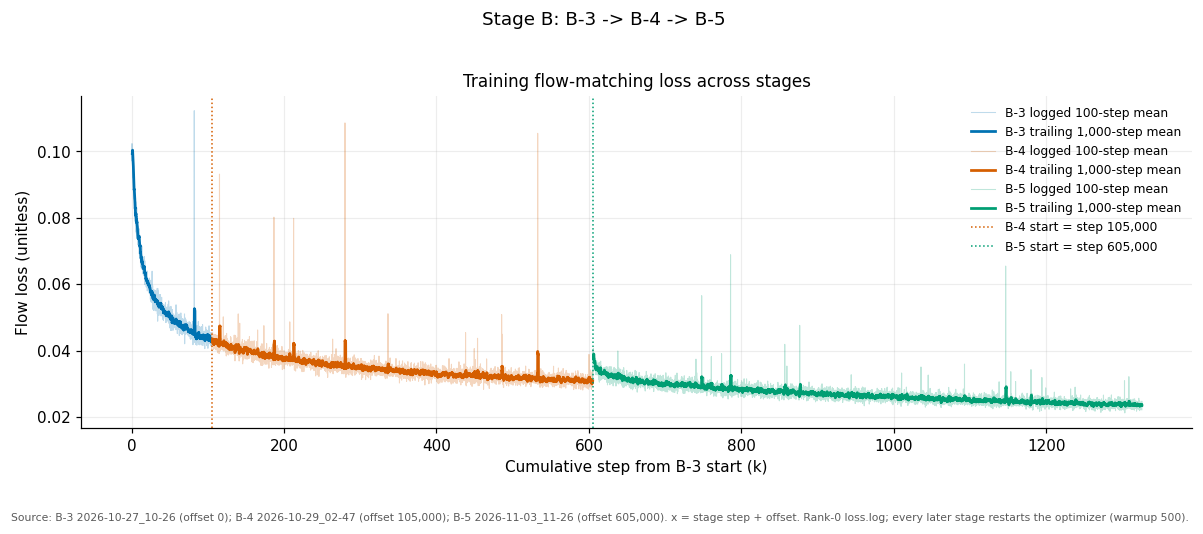

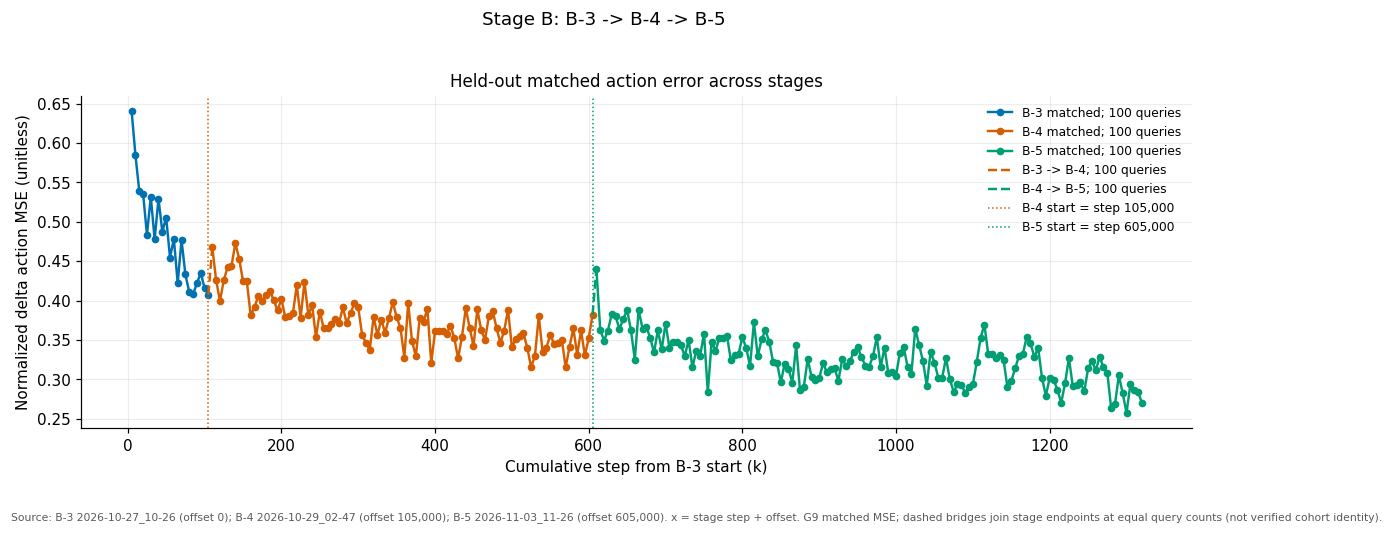

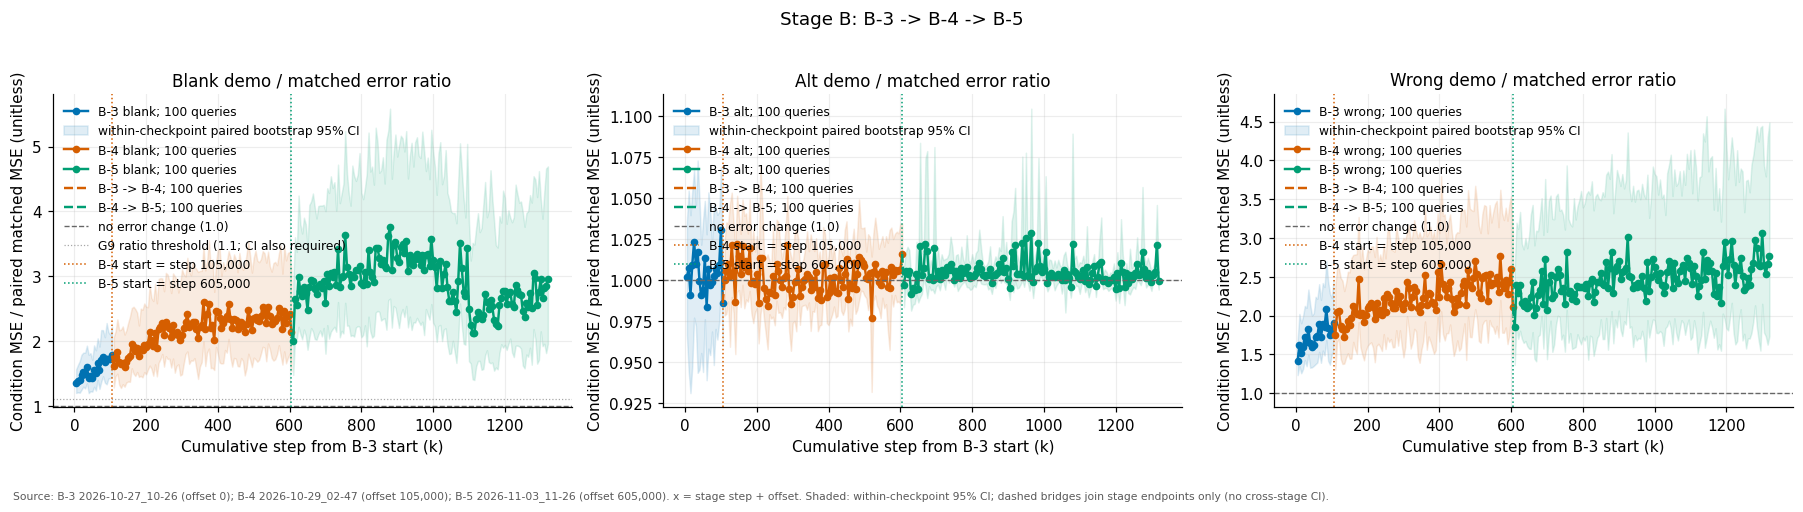

各阶段汇总（描述性，按阶段自己的步数）：


,stage,queries,evaluations,first_step,last_step,matched_first,matched_last,matched_min,matched_min_step,train_loss_1000_last,blank_ratio_last,blank_ci_last,alt_ratio_last,alt_ci_last,wrong_ratio_last,wrong_ci_last
0,B-3,100,21,5000,105000,0.6411,0.4075,0.4075,105000,0.0433,1.7780,"[1.463, 2.222]",0.9859,"[0.960, 1.015]",1.9095,"[1.541, 2.437]"
1,B-4,100,100,5000,500000,0.4677,0.3822,0.3152,465000,0.0309,2.1347,"[1.533, 3.085]",1.0160,"[0.997, 1.034]",2.1103,"[1.481, 3.073]"
2,B-5,100,143,5000,715000,0.4398,0.2701,0.2574,695000,0.0237,2.9581,"[1.959, 4.693]",0.9990,"[0.994, 1.005]",2.7648,"[1.735, 4.489]"


In [29]:
COMPARE = {'title': 'Stage B: ' + ' -> '.join(CTX), 'figures': {}, 'notes': [], 'report_dir': COMPARE_DIR}
CUM_XLABEL = 'Cumulative step from B-3 start (k)'
TRAINED = list(CTX.values())
EVALUATED = [c for c in CTX.values() if c['ckpt'] is not None]
SUMMARY = None


def stage_color(ctx):
    return STAGE_COLORS.get(ctx['name'], f'C{list(CTX).index(ctx["name"])}')


def stage_starts(ax):
    for ctx in CTX.values():
        if ctx['start']:
            ax.axvline(ctx['start'], color=stage_color(ctx), ls=':', lw=1.0, label=f"{ctx['name']} start = step {ctx['start']:,}")


def compare_caption(stages):
    parts = [f"{c['name']} {c['run'].name} (offset {c['start']:,})" for c in stages]
    return 'Source: ' + '; '.join(parts) + '. x = stage step + offset.'


def until_next_stage(ctx, df):
    # 一个阶段在下一阶段的起点截止（如 B-3 中断前的 105k-107.4k 不是 B-4 的前序）
    later = [c['start'] for c in CTX.values() if c['start'] > ctx['start']]
    return df[df['step'] + ctx['start'] <= min(later)] if later else df


def stage_bridges(ax, metric):
    # 用虚线连接阶段切换两端的实测点，不补造第 0 步评估，也不跨阶段填充 CI。
    stages = sorted(CTX.values(), key=lambda c: c['start'])
    for previous, current in zip(stages, stages[1:]):
        if previous['ckpt'] is None or current['ckpt'] is None:
            continue
        left = until_next_stage(previous, previous['ckpt'])
        right = until_next_stage(current, current['ckpt'])
        if metric not in left or metric not in right:
            continue
        # 前一阶段必须有恰好位于初始化 checkpoint 的评估；query 数也必须一致。
        boundary = left[left['step'] + previous['start'] == current['start']]
        for queries, group in right.groupby('queries', sort=True):
            anchor = boundary[boundary['queries'] == queries]
            if anchor.empty:
                continue
            first = group.sort_values('step').iloc[0]
            x = [current['start'], int(first['step']) + current['start']]
            y = [anchor.iloc[-1][metric], first[metric]]
            if x[1] <= x[0] or not np.isfinite(y).all():
                continue
            ax.plot(x, y, color=stage_color(current), ls='--', lw=1.6,
                    label=f"{previous['name']} -> {current['name']}; {int(queries)} queries")


if len(TRAINED) >= 2:
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for ctx in TRAINED:
        df = until_next_stage(ctx, ctx['train'])
        ax.plot(df['step'] + ctx['start'], df['loss'], color=stage_color(ctx), lw=0.7, alpha=0.25,
                label=f"{ctx['name']} logged {ctx['freq']}-step mean")
        ax.plot(df['step'] + ctx['start'], train_smooth(df, 'loss', ctx['freq']), color=stage_color(ctx), lw=1.8,
                label=f"{ctx['name']} trailing {SMOOTH_STEPS:,}-step mean")
    stage_starts(ax)
    finish_axis(ax, 'Training flow-matching loss across stages', 'Flow loss (unitless)', CUM_XLABEL)
    register(COMPARE, 'C1_train_loss', fig, compare_caption(TRAINED) + ' Rank-0 loss.log; every later stage restarts the optimizer (warmup 500).')

if len(EVALUATED) >= 2:
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for ctx in EVALUATED:
        evaluation_series(ax, until_next_stage(ctx, ctx['ckpt']), 'matched', color=stage_color(ctx), offset=ctx['start'],
                          label=f"{ctx['name']} ")
    stage_bridges(ax, 'matched')
    stage_starts(ax)
    finish_axis(ax, 'Held-out matched action error across stages', MSE_YLABEL, CUM_XLABEL)
    register(COMPARE, 'C2_matched', fig, compare_caption(EVALUATED) + ' G9 matched MSE; dashed bridges join stage endpoints at equal query counts (not verified cohort identity).')

    conditions = [c for c in ('blank', 'alt', 'wrong') if any(f'{c}_ratio' in x['ckpt'] for x in EVALUATED)]
    fig, axs = plt.subplots(1, len(conditions), figsize=(5.5 * len(conditions), 4.6), squeeze=False)
    for ax, cond in zip(axs[0], conditions):
        for i, ctx in enumerate(EVALUATED):
            ratio_series(ax, until_next_stage(ctx, ctx['ckpt']), cond, color=stage_color(ctx), offset=ctx['start'],
                         label=f"{ctx['name']} ", ci_label=(i == 0))
        stage_bridges(ax, f'{cond}_ratio')
        ratio_refs(ax, cond)
        stage_starts(ax)
        finish_axis(ax, f'{cond.capitalize()} demo / matched error ratio', RATIO_YLABEL, CUM_XLABEL)
    register(COMPARE, 'C3_g9_ratios', fig, compare_caption(EVALUATED) + ' Shaded: within-checkpoint 95% CI; dashed bridges join stage endpoints only (no cross-stage CI).')

    rows = []
    for ctx in EVALUATED:
        for queries, g in ctx['ckpt'].groupby('queries'):
            g = g.sort_values('step')
            first, last, best = g.iloc[0], g.iloc[-1], g.loc[g['matched'].idxmin()]
            row = {'stage': ctx['name'], 'queries': int(queries), 'evaluations': len(g),
                   'first_step': int(first.step), 'last_step': int(last.step),
                   'matched_first': first.matched, 'matched_last': last.matched,
                   'matched_min': best.matched, 'matched_min_step': int(best.step),
                   'train_loss_1000_last': last.get('train_loss_1000', np.nan)}
            for cond in ('blank', 'alt', 'wrong'):
                if f'{cond}_ratio' in g:
                    row[f'{cond}_ratio_last'] = last[f'{cond}_ratio']
                    row[f'{cond}_ci_last'] = f"[{last[f'{cond}_ci_low']:.3f}, {last[f'{cond}_ci_high']:.3f}]"
            rows.append(row)
    SUMMARY = pd.DataFrame(rows)
    print('各阶段汇总（描述性，按阶段自己的步数）：')
    display(SUMMARY.round(4))

if not COMPARE['figures']:
    print('对比图需要至少两个阶段有训练日志（或 G9）；当前有数据的阶段：' + ', '.join(CTX))

In [30]:
NOTES = [
    'Training loss is rank-0 interval-averaged flow loss, not an 8-GPU global mean.',
    'G9 errors are normalized-delta action MSE, not physical EE distances.',
    'Ratios / CI are read from paired-subset query-bootstrap results, never recomputed from all-query means.',
    'B-4 / B-5 G9 swap the P5 demo features (online encoding); validated against B-3 105k within 0.3%.',
    'B-5 starts from B-4 500k with the LoRA merged: G9 matched 0.383 vs 0.382 (b5_init_merged.json).',
    'Query IDs and seeds are not stored in the JSON; equal query counts do not verify cohort identity.',
    'No matched-error CI or cross-checkpoint significance is inferred.',
    'Source files may still be changing; the exported CSV files define the plotted snapshot.',
]


def source_info(paths):
    out = []
    for path in paths:
        stat = Path(path).stat()
        out.append({'path': str(path), 'bytes_at_export': stat.st_size,
                    'mtime_utc_at_export': datetime.fromtimestamp(stat.st_mtime, timezone.utc).isoformat()})
    return out


def export(target, tables, manifest):
    d = Path(target['report_dir'])
    d.mkdir(parents=True, exist_ok=True)
    for name, fig in target['figures'].items():
        for ext in FORMATS:
            fig.savefig(d / f'{name}.{ext}', dpi=DPI, bbox_inches='tight')
    for fname, df in tables.items():
        df.to_csv(d / fname, index=False)
    manifest.update({'generated_at_utc': datetime.now(timezone.utc).isoformat(), 'formats': list(FORMATS), 'dpi': DPI,
                     'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
                     'notes': NOTES, 'figures': target['notes']})
    (d / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
    print(f"已导出 {len(target['figures'])} 组图 × {len(FORMATS)} 格式 + {len(tables)} 份 CSV + manifest.json -> {d}")



if EXPORT and COMPARE['figures']:
    if not set(FORMATS).issubset({'png', 'pdf', 'svg'}):
        raise ValueError('FORMATS 仅支持 png / pdf / svg')
    paths = [p for c in CTX.values() for p in [c['run'] / 'loss.log'] + [r['path'] for r in c['records']]]
    export(COMPARE, {'stage_summary.csv': SUMMARY} if SUMMARY is not None else {},
           {'g9_dir': str(G9_DIR), 'exclude_files': sorted(EXCLUDE_FILES), 'query_counts': QUERY_COUNTS,
            'smooth_steps': SMOOTH_STEPS, 'train_window_steps': list(WINDOW_STEPS),
            'stages': [{'name': c['name'], 'run': str(c['run']), 'start_step': c['start'],
                        'evaluations': len(c['records'])} for c in CTX.values()],
            'sources': source_info(paths)})
else:
    print('EXPORT=False 或没有对比图：不写文件。')


已导出 3 组图 × 3 格式 + 1 份 CSV + manifest.json -> /home/jovyan/workspace/mytbot/outputs/BPv4CDX/stage_b/reports/stage_compare_b3_b5
